# 04 · Exploratory analysis and charts

Pull data out of the warehouse with SQL, shape it with pandas, and chart it with
matplotlib / seaborn. Every chart is also saved to `images/` for the README.

**Loans are SIMULATED; interest rates are REAL.** Every chart built on loan data says so.

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import seaborn as sns

from src.logger import get_logger

log = get_logger("04_analysis_and_charts")
sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("images", exist_ok=True)

# read_only: we only look at the warehouse here, never change it
con = duckdb.connect("data/warehouse.duckdb", read_only=True)

SIMULATED_NOTE = "Loan data is SIMULATED; interest rates are real (Bank of Canada)."


def save(fig, name):
    fig.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")
    log.info(f"Saved images/{name}.png")

## 1. The real rate story (2015 – 2026)
Fixed mortgages follow the 5-year bond yield; variable mortgages and HELOCs follow prime.
The shaded band is the low-rate era when the loans now renewing were signed.

2026-10-17 17:34:35,932 | 04_analysis_and_charts | INFO | Saved images/01_real_rates.png


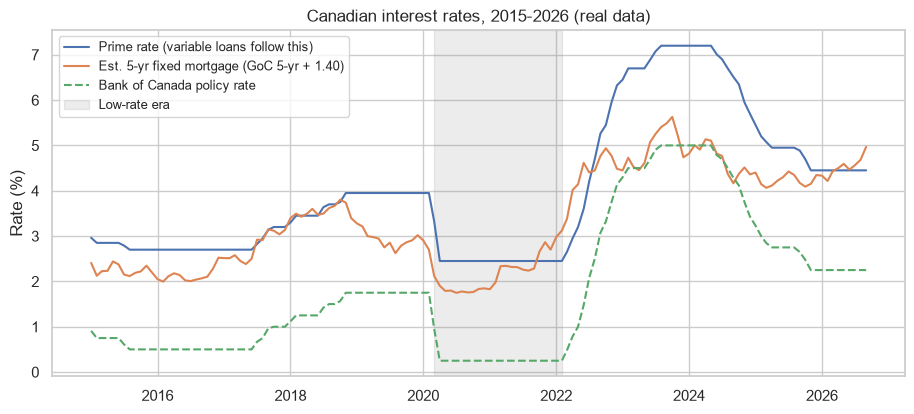

In [2]:
rates = con.sql("""
    SELECT month, policy_rate, prime_rate, goc_5yr_yield, est_5yr_fixed_mortgage_rate
    FROM mart.dim_month
    WHERE policy_rate IS NOT NULL
    ORDER BY month
""").df()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(rates["month"], rates["prime_rate"], label="Prime rate (variable loans follow this)")
ax.plot(rates["month"], rates["est_5yr_fixed_mortgage_rate"], label="Est. 5-yr fixed mortgage (GoC 5-yr + 1.40)")
ax.plot(rates["month"], rates["policy_rate"], label="Bank of Canada policy rate", linestyle="--")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2022-02-01"), color="grey", alpha=0.15, label="Low-rate era")
ax.set_title("Canadian interest rates, 2015-2026 (real data)")
ax.set_ylabel("Rate (%)")
ax.legend(loc="upper left", fontsize=9)
save(fig, "01_real_rates")
plt.show()

## 2. The renewal calendar
Each bar is one month's renewing balance. Grey = already renewed by Sep 2026 (the shock has
happened). Blue = still to come — the borrowers the bank can still reach.

2026-10-17 17:34:36,511 | 04_analysis_and_charts | INFO | Saved images/02_renewal_calendar.png


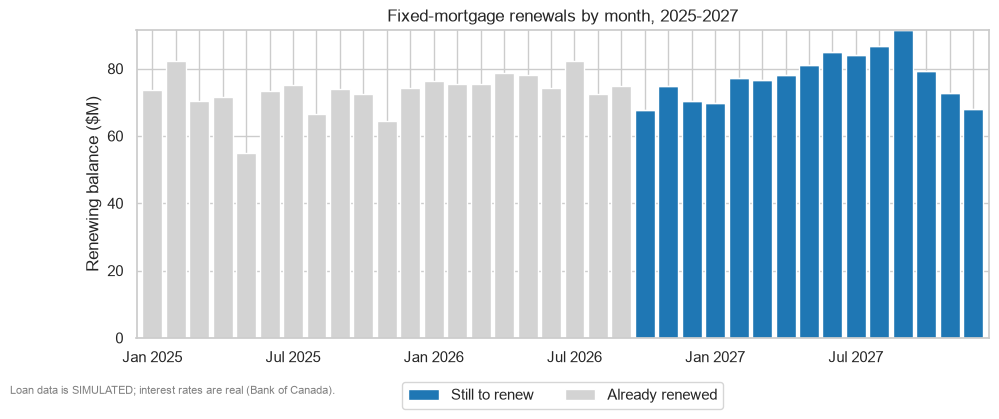

In [3]:
renewals = con.sql("SELECT * FROM mart.fact_renewal").df()

calendar = (
    renewals.groupby(["renewal_month", "already_renewed"])["balance_at_renewal"]
    .sum()
    .div(1e6)
    .unstack(fill_value=0)
    .rename(columns={True: "Already renewed", False: "Still to renew"})
)

fig, ax = plt.subplots(figsize=(11, 4))
calendar.plot(kind="bar", stacked=True, ax=ax, color=["tab:blue", "lightgrey"], width=0.85)
ax.legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_xticklabels([d.strftime("%b %Y") if d.month in (1, 7) else "" for d in calendar.index], rotation=0)
ax.set_title("Fixed-mortgage renewals by month, 2025-2027")
ax.set_xlabel("")
ax.set_ylabel("Renewing balance ($M)")
fig.text(0.01, -0.03, SIMULATED_NOTE, fontsize=8, color="grey")
save(fig, "02_renewal_calendar")
plt.show()

## 3. How big is the payment shock?
Distribution of the % increase in monthly payment, split by the year the current term started.

2026-10-17 17:34:37,120 | 04_analysis_and_charts | INFO | Saved images/03_payment_shock_distribution.png


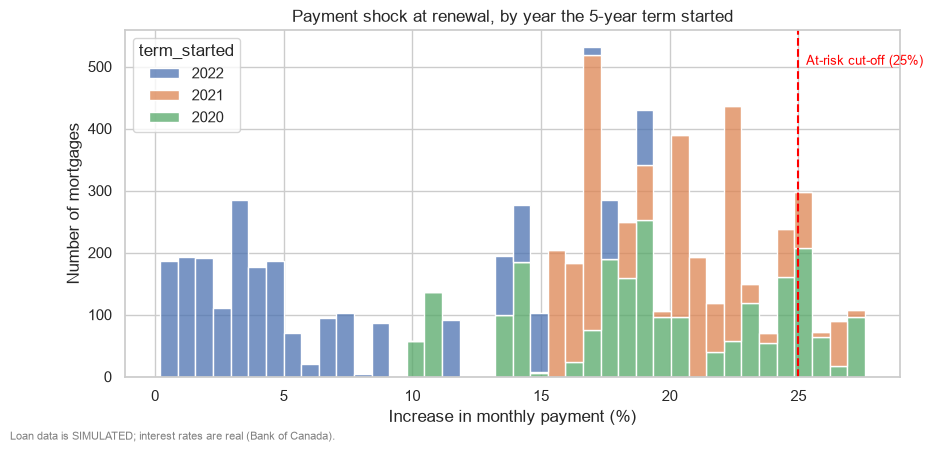

,count,mean,std,min,25%,50%,75%,max
term_started,,,,,,,,
2020,2189.0,19.5,4.7,10.4,16.7,19.1,23.6,27.6
2021,2250.0,19.9,3.2,15.2,16.9,20.2,22.4,27.0
2022,2277.0,6.4,5.5,0.2,1.7,4.2,11.2,19.1


In [4]:
renewals["term_started"] = (renewals["renewal_year"] - 5).astype(str)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(data=renewals, x="payment_shock_pct", hue="term_started", bins=40, multiple="stack", ax=ax)
ax.axvline(25, color="red", linestyle="--")
ax.text(25.3, ax.get_ylim()[1] * 0.9, "At-risk cut-off (25%)", color="red", fontsize=9)
ax.set_title("Payment shock at renewal, by year the 5-year term started")
ax.set_xlabel("Increase in monthly payment (%)")
ax.set_ylabel("Number of mortgages")
fig.text(0.01, -0.03, SIMULATED_NOTE, fontsize=8, color="grey")
save(fig, "03_payment_shock_distribution")
plt.show()

renewals.groupby("term_started")["payment_shock_pct"].describe().round(1)

**Takeaway:** terms started in 2020 and 2021 cluster around +15–25%; 2022 terms barely move.
The shock is a *timing* effect.

## 4. In dollars: what does the shock cost a household each month?
`pd.cut` puts each mortgage into a dollar band — easier for a stakeholder to read than percentages.

2026-10-17 17:34:37,659 | 04_analysis_and_charts | INFO | Saved images/04_payment_increase_dollars.png


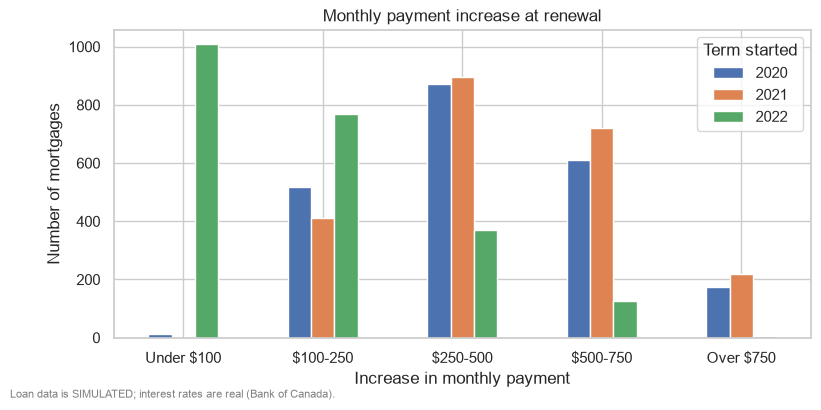

term_started,2020,2021,2022
increase_band,,,
Under $100,14,0,1008
$100-250,519,412,768
$250-500,872,897,370
$500-750,610,721,125
Over $750,174,220,6


In [5]:
renewals["increase_band"] = pd.cut(
    renewals["payment_increase"],
    bins=[-1, 100, 250, 500, 750, 10_000],
    labels=["Under $100", "$100-250", "$250-500", "$500-750", "Over $750"],
)
dollar_bands = (
    renewals.groupby(["increase_band", "term_started"], observed=False)
    .size()
    .unstack(fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 4))
dollar_bands.plot(kind="bar", ax=ax, rot=0)
ax.set_title("Monthly payment increase at renewal")
ax.set_xlabel("Increase in monthly payment")
ax.set_ylabel("Number of mortgages")
ax.legend(title="Term started")
fig.text(0.01, -0.04, SIMULATED_NOTE, fontsize=8, color="grey")
save(fig, "04_payment_increase_dollars")
plt.show()

dollar_bands

## 5. Delinquency over time, by product
Delinquency rate = delinquent balance ÷ total balance (30–120 days late). Calculated from summed
amounts, so a $700k mortgage counts more than a $5k card.

2026-10-17 17:34:38,199 | 04_analysis_and_charts | INFO | Saved images/05_delinquency_trend.png


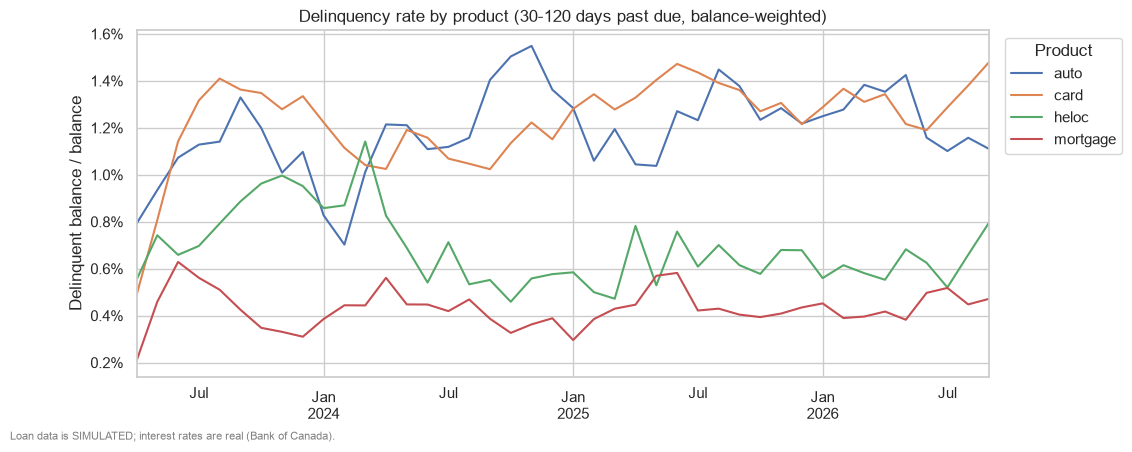

In [6]:
monthly = con.sql("""
    SELECT month, product,
           SUM(delinquent_balance) AS delinquent_balance,
           SUM(balance)            AS balance
    FROM mart.agg_portfolio_monthly
    GROUP BY month, product
""").df()
monthly["delinquency_rate"] = monthly["delinquent_balance"] / monthly["balance"]

trend = monthly.pivot(index="month", columns="product", values="delinquency_rate")

fig, ax = plt.subplots(figsize=(11, 4.5))
trend.plot(ax=ax)
ax.legend(title="Product", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.set_title("Delinquency rate by product (30-120 days past due, balance-weighted)")
ax.set_xlabel("")
ax.set_ylabel("Delinquent balance / balance")
fig.text(0.01, -0.03, SIMULATED_NOTE, fontsize=8, color="grey")
save(fig, "05_delinquency_trend")
plt.show()

**Takeaway:** the first couple of months run low because every loan starts the simulation
"current" in Apr 2023 — read the trend from mid-2023 on. Cards and auto loans run at roughly
2–3× the delinquency of mortgages, and HELOCs bump up during the 2023–24 prime-rate peak.

## 6. HELOC delinquency vs the prime rate
HELOC rates float with prime, so the 2023 spike should show up in HELOC delinquency.

2026-10-17 17:34:38,805 | 04_analysis_and_charts | INFO | Saved images/06_heloc_vs_prime.png


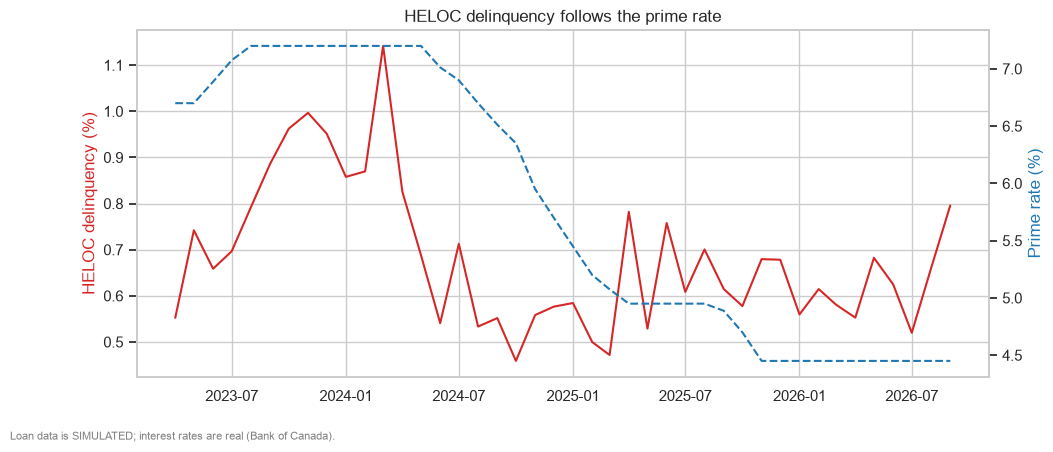

Correlation between prime rate and HELOC delinquency: 0.5


In [7]:
heloc = (monthly[monthly["product"] == "heloc"]
         .merge(rates[["month", "prime_rate"]], on="month")
         .sort_values("month"))  # sort by date, or the line zig-zags

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(heloc["month"], heloc["delinquency_rate"] * 100, color="tab:red", label="HELOC delinquency (left)")
ax1.set_ylabel("HELOC delinquency (%)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(heloc["month"], heloc["prime_rate"], color="tab:blue", linestyle="--", label="Prime rate (right)")
ax2.set_ylabel("Prime rate (%)", color="tab:blue")
ax2.grid(False)
ax1.set_title("HELOC delinquency follows the prime rate")
fig.text(0.01, -0.03, SIMULATED_NOTE, fontsize=8, color="grey")
save(fig, "06_heloc_vs_prime")
plt.show()

print("Correlation between prime rate and HELOC delinquency:",
      round(heloc["prime_rate"].corr(heloc["delinquency_rate"]), 2))

## 7. Default rate by product and credit band
42-month default rate for loans open in Apr 2023. Secured lending should default least,
unsecured most, and lower scores more.

2026-10-17 17:34:39,483 | 04_analysis_and_charts | INFO | Saved images/07_default_heatmap.png


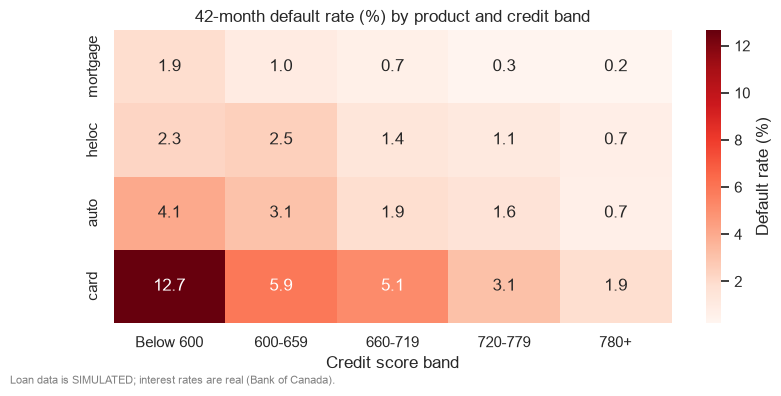

In [8]:
pd_table = con.sql("SELECT product, credit_band, default_rate_42m FROM mart.pd_by_segment").df()
heat = pd_table.pivot(index="product", columns="credit_band", values="default_rate_42m")
heat = heat.loc[["mortgage", "heloc", "auto", "card"], ["Below 600", "600-659", "660-719", "720-779", "780+"]]

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(heat * 100, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Default rate (%)"}, ax=ax)
ax.set_title("42-month default rate (%) by product and credit band")
ax.set_xlabel("Credit score band")
ax.set_ylabel("")
fig.text(0.01, -0.05, SIMULATED_NOTE, fontsize=8, color="grey")
save(fig, "07_default_heatmap")
plt.show()

**Takeaway:** credit cards in the "Below 600" band default at ~13% over 42 months, against ~0.2%
for 780+ mortgages. The ordering mortgage < HELOC < auto < card holds in every band except 780+, where HELOC
(0.74%) and auto (0.72%) are a near-tie. If cards looked safer than mortgages, something would be joined wrong.

## 8. Where the extra provision sits: province × credit band
A pivot table of incremental provision. The biggest cells are where to focus.

2026-10-17 17:34:40,118 | 04_analysis_and_charts | INFO | Saved images/08_provision_heatmap.png


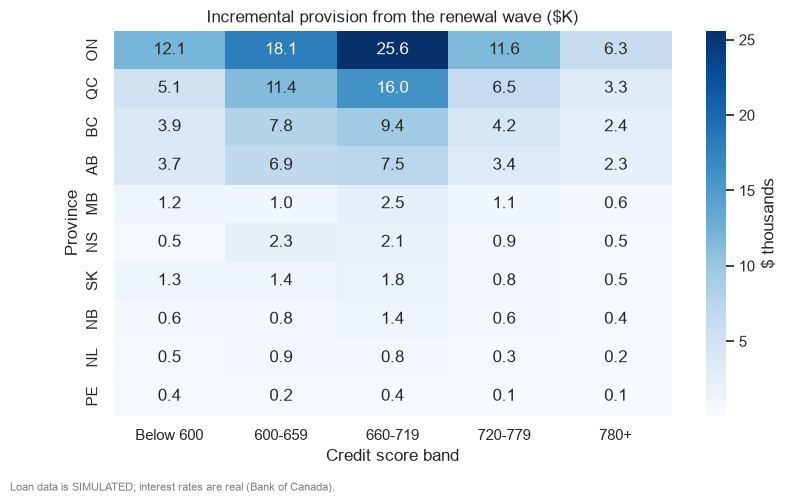

Total incremental provision: $193,428


In [9]:
provision = renewals.pivot_table(
    index="province", columns="credit_band", values="incremental_provision", aggfunc="sum", fill_value=0
)
provision = provision[["Below 600", "600-659", "660-719", "720-779", "780+"]]
provision = provision.loc[provision.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(provision / 1000, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "$ thousands"}, ax=ax)
ax.set_title("Incremental provision from the renewal wave ($K)")
ax.set_xlabel("Credit score band")
ax.set_ylabel("Province")
fig.text(0.01, -0.04, SIMULATED_NOTE, fontsize=8, color="grey")
save(fig, "08_provision_heatmap")
plt.show()

print(f"Total incremental provision: ${provision.values.sum():,.0f}")

## 9. A quick look at the call list
Of the borrowers who haven't renewed yet, how are the top 100 different from everyone else?

In [10]:
to_call = renewals[renewals["outreach_priority"].notna()].copy()
to_call["group"] = "Rest of list"
to_call.loc[to_call["outreach_priority"] <= 100, "group"] = "Top 100"

to_call.groupby("group").agg(
    borrowers=("loan_id", "count"),
    avg_credit_score=("credit_score", "mean"),
    avg_rate_jump_pp=("rate_jump_pp", "mean"),
    avg_monthly_increase=("payment_increase", "mean"),
    avg_extra_provision=("incremental_provision", "mean"),
).round(1)

,borrowers,avg_credit_score,avg_rate_jump_pp,avg_monthly_increase,avg_extra_provision
group,,,,,
Rest of list,2697,724.6,1.0,209.4,14.7
Top 100,100,613.0,2.0,592.4,106.3


In [11]:
con.close()